# Fund Performance Analytics

Bluestock FinTech Capstone task. Uses actual supplied NAV and benchmark datasets. Risk-free rate: 6.5% annual. Note: available NAV history is 2022-01-03 to 2026-05-29, so 5-year CAGR cannot be independently calculated; source-reported 5-year returns are preserved in the scorecard output.

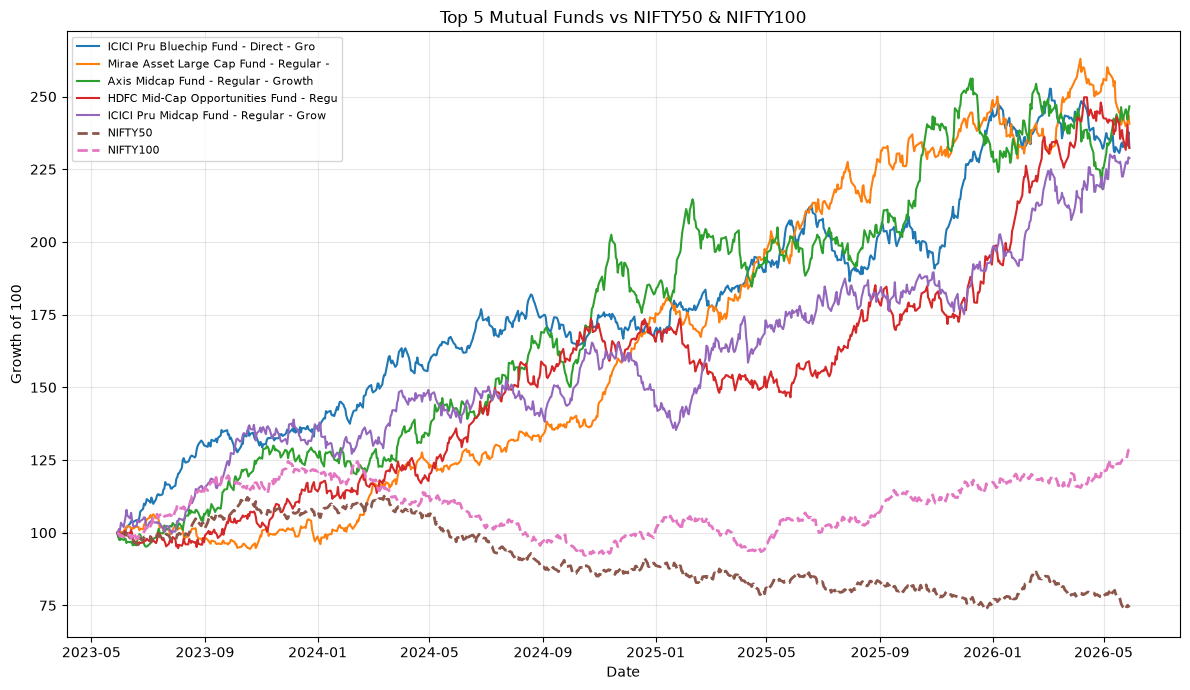

Completed. Output folder: C:\Users\Bheem\OneDrive\bheem bluedart\Fund_Performance_Analytics_Submission\Fund_Performance_Analytics_Submission\reports\outputs


In [4]:
# Fund Performance Analytics — Bluestock Capstone
# Place the 3 input CSVs in data/raw: 01_fund_master.csv, 02_nav_history.csv, 10_benchmark_indices.csv
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import linregress

ROOT = Path.cwd()
# If notebook is run from project root, use this path; otherwise adjust DATA_DIR.
DATA_DIR = ROOT / "data" / "raw"
OUT = ROOT / "reports" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
master = pd.read_csv(DATA_DIR / "01_fund_master.csv")
nav = pd.read_csv(DATA_DIR / "02_nav_history.csv", parse_dates=["date"]).sort_values(["amfi_code","date"])
bench = pd.read_csv(DATA_DIR / "10_benchmark_indices.csv", parse_dates=["date"]).sort_values(["index_name","date"])
nav["daily_return"] = nav.groupby("amfi_code")["nav"].pct_change()
nav["running_max"] = nav.groupby("amfi_code")["nav"].cummax()
nav["drawdown"] = nav["nav"] / nav["running_max"] - 1
bwide = bench.pivot(index="date", columns="index_name", values="close_value").sort_index()
bret = bwide.pct_change()
end = min(nav.date.max(), bench.date.max())
start3 = end - pd.DateOffset(years=3)

def cagr(g, years):
    g = g.sort_values("date"); last = g.iloc[-1]
    target = last.date - pd.DateOffset(years=years)
    prior = g[g.date <= target]
    if prior.empty: return np.nan
    first = prior.iloc[-1]; actual_years = (last.date-first.date).days/365.25
    return ((last.nav/first.nav)**(1/actual_years)-1)*100 if actual_years>0 and first.nav>0 else np.nan

rows=[]
for code,g in nav.groupby("amfi_code"):
    g=g.sort_values("date"); r=g[g.date>=start3]
    joined=r[["date","daily_return"]].merge(bret[["NIFTY100"]].reset_index(),on="date").dropna()
    if len(joined)>=30:
        reg=linregress(joined.NIFTY100, joined.daily_return); beta=reg.slope; alpha=reg.intercept*252*100
    else: alpha=beta=np.nan
    daily=r.daily_return.dropna(); ann=(1+daily).prod()**(252/len(daily))-1 if len(daily) else np.nan
    vol=daily.std()*np.sqrt(252) if len(daily)>1 else np.nan
    downside=daily[daily<0]; downvol=downside.std()*np.sqrt(252) if len(downside)>1 else np.nan
    rows.append({"amfi_code":code,"cagr_1yr_pct":cagr(g,1),"cagr_3yr_pct":cagr(g,3),"sharpe_ratio":(ann-.065)/vol if vol and vol>0 else np.nan,"sortino_ratio":(ann-.065)/downvol if downvol and downvol>0 else np.nan,"alpha_pct":alpha,"beta":beta,"max_drawdown_pct":g.drawdown.min()*100,"observations_3yr":len(joined)})
metrics=pd.DataFrame(rows).merge(master,on="amfi_code")
metrics["rank_3yr"]=metrics.cagr_3yr_pct.rank(pct=True)*100
metrics["rank_sharpe"]=metrics.sharpe_ratio.rank(pct=True)*100
metrics["rank_alpha"]=metrics.alpha_pct.rank(pct=True)*100
metrics["rank_expense_inverse"]=metrics.expense_ratio_pct.rank(ascending=False,pct=True)*100
metrics["rank_maxdd_inverse"]=metrics.max_drawdown_pct.rank(pct=True)*100
metrics["fund_score_0_100"]=(.30*metrics.rank_3yr+.25*metrics.rank_sharpe+.20*metrics.rank_alpha+.15*metrics.rank_expense_inverse+.10*metrics.rank_maxdd_inverse).round(2)
metrics=metrics.sort_values("fund_score_0_100",ascending=False)
metrics.to_csv(OUT/"fund_scorecard.csv",index=False)
metrics[["amfi_code","scheme_name","alpha_pct","beta","observations_3yr"]].to_csv(OUT/"alpha_beta.csv",index=False)
# 5-year CAGR cannot be computed from NAV history: available period is under 5 years.
# Benchmark comparison chart: top 5 scorecard funds vs NIFTY50 and NIFTY100.
fig,ax=plt.subplots(figsize=(12,7))
for _,row in metrics.head(5).iterrows():
    g=nav[(nav.amfi_code==row.amfi_code)&(nav.date>=start3)].sort_values("date")
    ax.plot(g.date,g.nav/g.nav.iloc[0]*100,label=row.scheme_name[:38])
for idx in ["NIFTY50","NIFTY100"]:
    s=bwide[idx].dropna(); s=s[s.index>=start3]; ax.plot(s.index,s/s.iloc[0]*100,"--",linewidth=2,label=idx)
ax.set(title="Top 5 Mutual Funds vs NIFTY50 & NIFTY100",ylabel="Growth of 100",xlabel="Date"); ax.grid(alpha=.3); ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT/"Benchmark_Comparison.png",dpi=180); plt.show()
print("Completed. Output folder:", OUT)
